In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report
from sklearn import metrics
from sklearn import tree
import warnings
warnings.filterwarnings("ignore")

In [38]:
url = "/Users/koushik/ML PROJECT/Crop_recommendation.csv"
df = pd.read_csv(url)

In [39]:
print("****"*20)
print("First Five Rows: ")
print("****"*20)
display(df.head())
print("****"*20)
print()
print("****"*20)
print("Last Five Rows: ")
print("****"*20)
display(df.tail())
print("****"*20)
print()
print("****"*20)
print("Description About the DataSet: ")
print("****"*20)
display(df.describe())
print("****"*20)
print()
print("****"*20)
print("Information About the DataSet: ")
print("****"*20)
display(df.info())
print("****"*20)

print("Size of dataset: ",df.size)
print("Shape of dataset: ",df.shape)

********************************************************************************
First Five Rows: 
********************************************************************************


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


********************************************************************************

********************************************************************************
Last Five Rows: 
********************************************************************************


,N,P,K,temperature,humidity,ph,rainfall,label
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,coffee
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,coffee
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,coffee
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,coffee
2199,104,18,30,23.603016,60.396475,6.779833,140.937041,coffee


********************************************************************************

********************************************************************************
Description About the DataSet: 
********************************************************************************


,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


********************************************************************************

********************************************************************************
Information About the DataSet: 
********************************************************************************
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


None

********************************************************************************
Size of dataset:  17600
Shape of dataset:  (2200, 8)


In [40]:
display(df.columns)

Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='object')

In [41]:
df['label'].unique()

array(['rice', 'maize', 'chickpea', 'kidneybeans', 'pigeonpeas',
       'mothbeans', 'mungbean', 'blackgram', 'lentil', 'pomegranate',
       'banana', 'mango', 'grapes', 'watermelon', 'muskmelon', 'apple',
       'orange', 'papaya', 'coconut', 'cotton', 'jute', 'coffee'],
      dtype=object)

In [42]:
df.dtypes

N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label           object
dtype: object

In [43]:
df['label'].value_counts()

label
rice           100
maize          100
jute           100
cotton         100
coconut        100
papaya         100
orange         100
apple          100
muskmelon      100
watermelon     100
grapes         100
mango          100
banana         100
pomegranate    100
lentil         100
blackgram      100
mungbean       100
mothbeans      100
pigeonpeas     100
kidneybeans    100
chickpea       100
coffee         100
Name: count, dtype: int64

<Axes: >

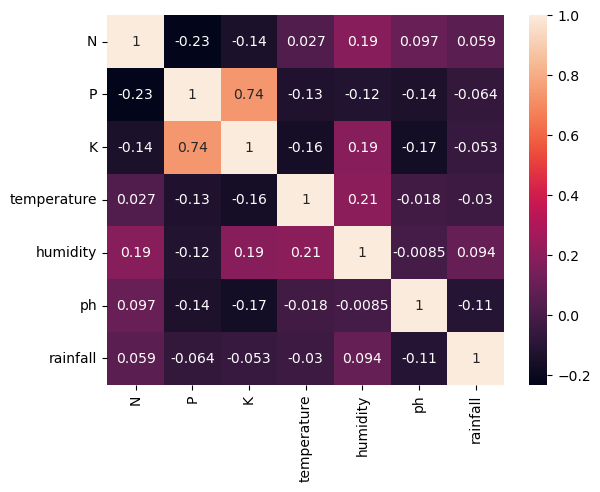

In [44]:
sns.heatmap(df.select_dtypes(include="number").corr(),annot=True)

In [45]:
features = df[df.select_dtypes(include="number").columns.tolist()]
target = df['label']
labels = df['label']

In [46]:
features.shape
display(target.shape)

(2200,)

In [47]:
acc = []
model = []

In [48]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(features,target,test_size=0.2,random_state=2,stratify=target)

In [49]:
# DT MODEL

from sklearn.tree import DecisionTreeClassifier
decisionTree = DecisionTreeClassifier(criterion="entropy",max_depth=5,random_state=2)
decisionTree.fit(X_train,y_train)

predicted_values = decisionTree.predict(X_test)

x = metrics.accuracy_score(y_test, predicted_values)
acc.append(x)
model.append('Decision Tree')
print("DecisionTrees's Accuracy is: ", x*100)

print(classification_report(y_test,predicted_values))

DecisionTrees's Accuracy is:  92.04545454545455
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       0.95      1.00      0.98        20
   blackgram       0.59      1.00      0.74        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      0.95      0.97        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       1.00      0.30      0.46        20
 kidneybeans       1.00      0.70      0.82        20
      lentil       0.90      0.90      0.90        20
       maize       0.95      1.00      0.98        20
       mango       1.00      0.95      0.97        20
   mothbeans       0.83      0.50      0.62        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00

In [50]:
from sklearn.model_selection import cross_val_score

score = cross_val_score(decisionTree,features,target,cv=5)

In [51]:
score

array([0.93636364, 0.90909091, 0.91818182, 0.87045455, 0.93636364])

In [52]:
import pickle 

DT_pkl_filename = 'DecisionTree.pkl'

# Open the file to save as pkl file
DT_Model_pkl = open(DT_pkl_filename, 'wb')
pickle.dump(decisionTree, DT_Model_pkl)
# Close the pickle instances
DT_Model_pkl.close()

In [53]:
from sklearn.naive_bayes import GaussianNB

NaiveBayes = GaussianNB()

NaiveBayes.fit(X_train,y_train)

predicted_values = NaiveBayes.predict(X_test)
x = metrics.accuracy_score(y_test, predicted_values)
acc.append(x)
model.append('Naive Bayes')
print("Naive Bayes's Accuracy is: ", x)

print(classification_report(y_test,predicted_values))

Naive Bayes's Accuracy is:  1.0
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       1.00      1.00      1.00        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00      

In [54]:
# Cross validation score (NaiveBayes)
score = cross_val_score(NaiveBayes,features,target,cv=5)
score

array([0.99772727, 0.99545455, 0.99545455, 0.99545455, 0.99090909])

In [55]:
import pickle
# Dump the trained Naive Bayes classifier with Pickle
NB_pkl_filename = 'NBClassifier.pkl'
# Open the file to save as pkl file
NB_Model_pkl = open(NB_pkl_filename, 'wb')
pickle.dump(NaiveBayes, NB_Model_pkl)
# Close the pickle instances
NB_Model_pkl.close()

In [56]:
from sklearn.svm import SVC

SVM = SVC(gamma='auto')

SVM.fit(X_train,y_train)

predicted_values = SVM.predict(X_test)

x = metrics.accuracy_score(y_test, predicted_values)
acc.append(x)
model.append('SVM')
print("SVM's Accuracy is: ", x)

print(classification_report(y_test,predicted_values))

SVM's Accuracy is:  0.27045454545454545
              precision    recall  f1-score   support

       apple       1.00      0.30      0.46        20
      banana       1.00      0.25      0.40        20
   blackgram       1.00      0.25      0.40        20
    chickpea       1.00      0.45      0.62        20
     coconut       1.00      0.20      0.33        20
      coffee       1.00      0.05      0.10        20
      cotton       1.00      0.35      0.52        20
      grapes       1.00      0.40      0.57        20
        jute       1.00      0.15      0.26        20
 kidneybeans       1.00      0.10      0.18        20
      lentil       1.00      0.10      0.18        20
       maize       1.00      0.10      0.18        20
       mango       1.00      0.20      0.33        20
   mothbeans       0.67      0.10      0.17        20
    mungbean       1.00      0.35      0.52        20
   muskmelon       1.00      0.65      0.79        20
      orange       1.00      0.25      0.

In [57]:
# Cross validation score (SVM)
score = cross_val_score(SVM,features,target,cv=5)
score

array([0.27727273, 0.28863636, 0.29090909, 0.275     , 0.26818182])

In [58]:
from sklearn.linear_model import LogisticRegression

LogReg = LogisticRegression(random_state=2)

LogReg.fit(X_train,y_train)

predicted_values = LogReg.predict(X_test)

x = metrics.accuracy_score(y_test, predicted_values)
acc.append(x)
model.append('Logistic Regression')
print("Logistic Regression's Accuracy is: ", x)

print(classification_report(y_test,predicted_values))

Logistic Regression's Accuracy is:  0.9636363636363636
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       0.95      1.00      0.98        20
   blackgram       0.83      0.95      0.88        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       0.95      0.95      0.95        20
      grapes       1.00      1.00      1.00        20
        jute       0.86      0.95      0.90        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      0.85      0.92        20
       maize       0.95      0.90      0.92        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.88      0.75      0.81        20
    mungbean       0.91      1.00      0.95        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00   

In [59]:
# Cross validation score (Logistic Regression)
score = cross_val_score(LogReg,features,target,cv=5)
score

array([0.95      , 0.96590909, 0.94772727, 0.96590909, 0.94318182])

In [60]:
import pickle

with open("LogisticRegression.pkl", "wb") as file:
    pickle.dump(LogReg, file)

In [61]:
from sklearn.ensemble import RandomForestClassifier

RF = RandomForestClassifier(n_estimators=20, random_state=0)
RF.fit(X_train,y_train)

predicted_values = RF.predict(X_test)

x = metrics.accuracy_score(y_test, predicted_values)
acc.append(x)
model.append('RF')
print("RF's Accuracy is: ", x)

print(classification_report(y_test,predicted_values))

RF's Accuracy is:  0.9977272727272727
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00

In [62]:
# Cross validation score (Random Forest)
score = cross_val_score(RF,features,target,cv=5)
score

array([0.99772727, 0.99545455, 0.99772727, 0.99318182, 0.98863636])

In [63]:
import pickle
# Dump the trained Naive Bayes classifier with Pickle
RF_pkl_filename = 'RandomForest.pkl'
# Open the file to save as pkl file
RF_Model_pkl = open(RF_pkl_filename, 'wb')
pickle.dump(RF, RF_Model_pkl)
# Close the pickle instances
RF_Model_pkl.close()

In [64]:

# 1. Import required libraries
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
from sklearn.metrics import classification_report

# 2. Encode target labels
le = LabelEncoder()

y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

# 3. Initialize XGBoost classifier
XB = XGBClassifier(
    objective='multi:softprob',
    num_class=len(le.classes_),
    eval_metric='mlogloss',
    random_state=42
)

# 4. Train the model
XB.fit(X_train, y_train_encoded)

# 5. Make predictions
predicted_values = XB.predict(X_test)

# 6. Calculate accuracy
x = metrics.accuracy_score(y_test_encoded, predicted_values)

# 7. Store accuracy and model name
acc.append(x)
model.append('XGBoost')

# 8. Print accuracy
print("XGBoost's Accuracy is:", x)

# 9. Display classification report
print(classification_report(
    y_test_encoded,
    predicted_values,
    labels=range(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0
))

# 10. Convert numerical predictions back to crop names
predicted_crops = le.inverse_transform(predicted_values)

print("First 10 predicted crops:")
print(predicted_crops[:10])


XGBoost's Accuracy is: 0.990909090909091
              precision    recall  f1-score   support

       apple       0.95      1.00      0.98        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      0.95      0.97        20
        jute       0.95      0.95      0.95        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      0.95      0.97        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.95      1.00      0.98        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1

In [65]:

from sklearn.model_selection import cross_val_score

# 1. Select actual numerical features
X_cv = df.select_dtypes(include="number")

# 2. Encode target labels using the existing encoder
y_cv = le.transform(df['label'])

# 3. Initialize a fresh XGBoost model
XB_cv = XGBClassifier(
    objective='multi:softprob',
    num_class=len(le.classes_),
    eval_metric='mlogloss',
    random_state=42
)

# 4. Perform 5-fold cross-validation
score = cross_val_score(
    XB_cv,
    X_cv,
    y_cv,
    cv=5,
    scoring='accuracy'
)

# 5. Display individual scores
print("Cross-validation scores:", score)

# 6. Calculate average accuracy
print("Average CV Accuracy:", score.mean())
print("Average CV Accuracy (%):", score.mean() * 100)


Cross-validation scores: [0.99545455 0.99090909 0.99545455 0.99318182 0.99090909]
Average CV Accuracy: 0.9931818181818182
Average CV Accuracy (%): 99.31818181818181


In [66]:
import pickle
# Dump the trained Naive Bayes classifier with Pickle
XB_pkl_filename = 'XGBoost.pkl'
# Open the file to save as pkl file
XB_Model_pkl = open(XB_pkl_filename, 'wb')
pickle.dump(XB, XB_Model_pkl)
# Close the pickle instances
XB_Model_pkl.close()

<Axes: title={'center': 'Accuracy Comparison'}, xlabel='Accuracy', ylabel='Algorithm'>

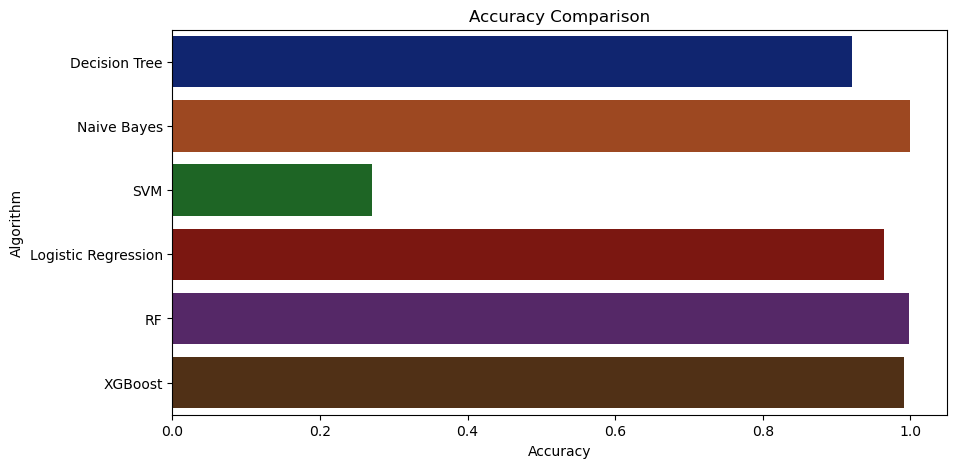

In [67]:
plt.figure(figsize=[10,5],dpi = 100)
plt.title('Accuracy Comparison')
plt.xlabel('Accuracy')
plt.ylabel('Algorithm')
sns.barplot(x = acc,y = model,palette='dark')

In [68]:
accuracy_models = dict(zip(model, acc))
for k, v in accuracy_models.items():
    print (k, '-->', v)

Decision Tree --> 0.9204545454545454
Naive Bayes --> 1.0
SVM --> 0.27045454545454545
Logistic Regression --> 0.9636363636363636
RF --> 0.9977272727272727
XGBoost --> 0.990909090909091


In [69]:
data = np.array([[104,18, 30, 23.603016, 60.3, 6.7, 140.91]])
prediction = RF.predict(data)
print(prediction)

['coffee']


In [70]:
data = np.array([[83, 45, 60, 28, 70.3, 7.0, 150.9]])
prediction = RF.predict(data)
print(prediction)

['jute']


In [71]:

import joblib

# Save model and its required metadata together
model_artifact = {
    "model": RF,
    "feature_names": features.columns.tolist(),
    "model_name": "Random Forest",
    "classes": RF.classes_.tolist()
}

joblib.dump(
    model_artifact,
    "crop_recommendation_model.joblib"
)

print("Model saved successfully!")
print("Features:", model_artifact["feature_names"])
print("Crop classes:", len(model_artifact["classes"]))


Model saved successfully!
Features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Crop classes: 22


In [72]:
import joblib

# Load the saved artifact
artifact = joblib.load("crop_recommendation_model.joblib")

# Extract the model
loaded_model = artifact["model"]

# Check metadata
print("Model:", artifact["model_name"])
print("Features:", artifact["feature_names"])
print("Crop classes:", artifact["classes"])

Model: Random Forest
Features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Crop classes: ['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']
